# Rideshare Dataset Enrichment

This notebook takes `trip_reviews.csv` and
1. creates a synthetic rider pool,
2. assigns riders to trips,
3. injects rule based rating shifts,
4. rewrites review text for trips with a shift of at least 0.3 stars,
5. exports `biased_trip_reviews_final.xlsx`.

All random draws use seed 42. The output reproduces the released `biased_trip_reviews_final.xlsx` exactly.

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import random
from tqdm import tqdm

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tqdm.pandas()

## 1. Load base dataset

In [2]:
df = pd.read_csv("trip_reviews.csv")
print(f"Loaded {len(df)} trips, {df.columns.size} columns")
print(f"Unique drivers: {df['driver_id'].nunique()}")
print(df["star_rating_int"].value_counts().sort_index())

Loaded 9158 trips, 36 columns
Unique drivers: 179
star_rating_int
1      13
2     329
3    2898
4    5753
5     165
Name: count, dtype: int64


## 2. Synthetic rider pool

| Attribute | Values and probabilities |
|---|---|
| Gender | male 0.48, female 0.47, non binary 0.05 |
| Age group | young 18 to 29 (0.40), middle 30 to 49 (0.40), senior 50 to 74 (0.20) |
| Borough | Manhattan 0.35, Brooklyn 0.25, Queens 0.20, Bronx 0.12, Staten Island 0.08 |
| Tier | frequent 0.15, regular 0.35, occasional 0.35, new 0.15 |
| Personality | lenient 0.25, neutral 0.50, critical 0.25 |

In [3]:
NUM_RIDERS = 800

first_names_male = [
    "James", "Michael", "David", "Carlos", "Mohammed", "Wei", "Raj",
    "Andre", "Marcus", "Ivan", "Tomás", "Hiroshi", "Brian", "Kevin",
    "Omar", "Diego", "Yusuf", "Nathan", "Jamal", "Ethan", "Luis",
    "Antonio", "Kwame", "Sanjay", "Dmitri", "Hassan", "Patrick",
    "Samuel", "Tyler", "Jerome", "Aiden", "Malik", "Chen", "Roberto",
    "Trevor", "Darren", "Kofi", "Tariq", "Vincent", "Alex"
]
first_names_female = [
    "Jessica", "Maria", "Aisha", "Priya", "Mei", "Sarah", "Fatima",
    "Keisha", "Yuki", "Elena", "Gabriela", "Ngozi", "Ashley", "Tanya",
    "Lakshmi", "Rosa", "Aaliyah", "Svetlana", "Chloe", "Brittany",
    "Jasmine", "Linda", "Amara", "Sofia", "Danielle", "Monique",
    "Xiaoli", "Abigail", "Zara", "Kiara", "Nadia", "Carmen",
    "Destiny", "Rachel", "Hana", "Courtney", "Ines", "Tamika",
    "Megan", "Ananya"
]
first_names_nb = [
    "Jordan", "Taylor", "Riley", "Casey", "Quinn", "Avery",
    "Sage", "Rowan", "Kai", "Dakota"
]
last_names = [
    "Smith", "Johnson", "Williams", "Garcia", "Martinez", "Lee",
    "Kim", "Patel", "Brown", "Davis", "Rodriguez", "Wilson",
    "Chen", "Thomas", "Jackson", "White", "Harris", "Clark",
    "Lewis", "Robinson", "Walker", "Hall", "Allen", "Young",
    "King", "Wright", "Lopez", "Hill", "Scott", "Green",
    "Adams", "Baker", "Gonzalez", "Nelson", "Carter", "Mitchell",
    "Perez", "Roberts", "Turner", "Phillips", "Campbell", "Parker",
    "Evans", "Edwards", "Collins", "Stewart", "Sanchez", "Morris",
    "Rogers", "Reed", "Cook", "Morgan", "Bell", "Murphy",
    "Rivera", "Cooper", "Richardson", "Cox", "Howard", "Ward"
]

genders, gender_probs = ["male", "female", "non-binary"], [0.48, 0.47, 0.05]
age_groups, age_probs = ["young", "middle", "senior"], [0.40, 0.40, 0.20]
boroughs, borough_probs = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"], [0.35, 0.25, 0.20, 0.12, 0.08]
tiers, tier_probs = ["frequent", "regular", "occasional", "new"], [0.15, 0.35, 0.35, 0.15]
personalities, pers_probs = ["lenient", "neutral", "critical"], [0.25, 0.50, 0.25]

riders, used_names = [], set()
for i in range(NUM_RIDERS):
    gender = np.random.choice(genders, p=gender_probs)
    if gender == "male":
        first = random.choice(first_names_male)
    elif gender == "female":
        first = random.choice(first_names_female)
    else:
        first = random.choice(first_names_nb)
    last = random.choice(last_names)
    full_name = f"{first} {last}"
    if full_name in used_names:
        full_name = f"{first} {last} {i}"
    used_names.add(full_name)
    age_group = np.random.choice(age_groups, p=age_probs)
    if age_group == "young":
        age = np.random.randint(18, 30)
    elif age_group == "middle":
        age = np.random.randint(30, 50)
    else:
        age = np.random.randint(50, 75)
    riders.append({
        "rider_id": f"RIDER_{i:04d}",
        "rider_name": full_name,
        "rider_gender": gender,
        "rider_age": age,
        "rider_age_group": age_group,
        "rider_borough": np.random.choice(boroughs, p=borough_probs),
        "rider_tier": np.random.choice(tiers, p=tier_probs),
        "rider_personality": np.random.choice(personalities, p=pers_probs),
    })

rider_df = pd.DataFrame(riders)
rider_df.to_csv("riders.csv", index=False)
rider_df.to_excel("riders.xlsx", index=False)
print(f"Created {len(rider_df)} riders")
for col in ["rider_gender", "rider_age_group", "rider_borough", "rider_tier", "rider_personality"]:
    print(rider_df[col].value_counts().to_dict())

Created 800 riders
{np.str_('male'): 391, np.str_('female'): 368, np.str_('non-binary'): 41}
{np.str_('middle'): 323, np.str_('young'): 317, np.str_('senior'): 160}
{np.str_('Manhattan'): 257, np.str_('Brooklyn'): 220, np.str_('Queens'): 169, np.str_('Bronx'): 85, np.str_('Staten Island'): 69}
{np.str_('occasional'): 293, np.str_('regular'): 270, np.str_('frequent'): 123, np.str_('new'): 114}
{np.str_('neutral'): 406, np.str_('lenient'): 206, np.str_('critical'): 188}


## 3. Assign riders to trips

Each trip receives one rider drawn with replacement. Tier weights are 8.0 (frequent), 4.0 (regular), 1.5 (occasional), and 0.5 (new).

In [4]:
tier_weights = {"frequent": 8.0, "regular": 4.0, "occasional": 1.5, "new": 0.5}
weights = rider_df["rider_tier"].map(tier_weights).values
weights = weights / weights.sum()
assigned_indices = np.random.choice(len(rider_df), size=len(df), p=weights)

rider_cols = ["rider_id", "rider_name", "rider_gender", "rider_age",
              "rider_age_group", "rider_borough", "rider_tier", "rider_personality"]
rider_assignments = rider_df.iloc[assigned_indices][rider_cols].reset_index(drop=True)
df = pd.concat([df.reset_index(drop=True), rider_assignments], axis=1)

print(df["rider_tier"].value_counts().to_dict())
print(f"Riders with at least one trip: {df['rider_id'].nunique()} of {len(rider_df)}")
print(f"Average trips per assigned rider: {len(df) / df['rider_id'].nunique():.1f}")

{np.str_('regular'): 3788, np.str_('frequent'): 3584, np.str_('occasional'): 1562, np.str_('new'): 224}
Riders with at least one trip: 783 of 800
Average trips per assigned rider: 11.7


## 4. Rating shifts

All applicable shifts are added together, so their order does not matter.

| Rule | Condition | Shift |
|---|---|---|
| 1 | Personality lenient / critical | +0.30 / −0.30 |
| 2 | Tier frequent / occasional / new | −0.20 / +0.05 / +0.15 |
| 3 | Age group young / senior | −0.10 / +0.20 |
| 4 | Late night pickup and critical rider | −0.30 |
| 5 | Rain or snow and new rider | −0.25 |
| 6 | Wait above 75th percentile and frequent rider | −0.30 |
| 7 | Fare above 75th percentile and young rider | −0.20 |
| 8 | Rider lives outside Manhattan and pickup in Manhattan | −0.15 |

Gaussian noise with standard deviation 0.08 is added, the result is clipped to the range 1 to 5 and rounded to one decimal place. Tips are scaled by one plus 0.1 times the shift, limited to the range 0.5 to 1.5.

In [5]:
df["original_star_rating"] = df["star_rating"].copy()
df["original_star_rating_int"] = df["star_rating_int"].copy()
biased_rating = df["star_rating"].copy()

biased_rating += df["rider_personality"].map({"lenient": 0.3, "neutral": 0.0, "critical": -0.3})
biased_rating += df["rider_tier"].map({"frequent": -0.2, "regular": 0.0, "occasional": 0.05, "new": 0.15})
biased_rating += df["rider_age_group"].map({"young": -0.1, "middle": 0.0, "senior": 0.2})

late_critical = (df["is_late_night"] == True) & (df["rider_personality"] == "critical")
biased_rating[late_critical] -= 0.3

bad_weather = (df["pickup_is_rain"] == True) | (df["pickup_is_snow"] == True)
biased_rating[bad_weather & (df["rider_tier"] == "new")] -= 0.25

wait_q75 = df["wait_time_mins"].quantile(0.75)
biased_rating[(df["wait_time_mins"] > wait_q75) & (df["rider_tier"] == "frequent")] -= 0.3

fare_q75 = df["fare_amount"].quantile(0.75)
biased_rating[(df["fare_amount"] > fare_q75) & (df["rider_age_group"] == "young")] -= 0.2

manhattan_zones = {
    4,12,13,24,41,42,43,45,48,50,68,74,75,79,87,88,90,100,103,104,105,107,
    113,114,116,120,125,127,128,137,140,141,142,143,144,148,151,152,153,158,
    161,162,163,164,166,170,186,194,202,209,211,224,229,230,231,232,233,234,
    236,237,238,239,243,244,246,249,261,262,263
}
outer_boroughs = ["Brooklyn", "Queens", "Bronx", "Staten Island"]
borough_mismatch = df["rider_borough"].isin(outer_boroughs) & df["PULocationID"].isin(manhattan_zones)
biased_rating[borough_mismatch] -= 0.15

biased_rating += np.random.normal(0, 0.08, size=len(df))
biased_rating = biased_rating.clip(1.0, 5.0)
df["star_rating"] = biased_rating.round(1)
df["star_rating_int"] = biased_rating.round(0).astype(int).clip(1, 5)

rating_shift = df["star_rating"] - df["original_star_rating"]
tip_multiplier = (1 + rating_shift * 0.1).clip(0.5, 1.5)
df["tip_amount"] = (df["tip_amount"] * tip_multiplier).round(2)
df["tip_ratio"] = (df["tip_amount"] / df["fare_amount"]).round(6)
df["rating_shift"] = (df["star_rating"] - df["original_star_rating"]).round(2)

print(f"Wait time 75th percentile: {wait_q75:.2f} minutes")
print(f"Fare 75th percentile: {fare_q75:.2f}")
print(f"Trips with any shift: {(df['rating_shift'] != 0).sum()} ({(df['rating_shift'] != 0).mean()*100:.1f}%)")
print(f"Mean shift: {df['rating_shift'].mean():.3f}, std: {df['rating_shift'].std():.3f}")
print(df.groupby("rider_personality")["star_rating"].mean().round(2).to_dict())

Wait time 75th percentile: 5.47 minutes
Fare 75th percentile: 35.27
Trips with any shift: 8040 (87.8%)
Mean shift: -0.142, std: 0.331
{np.str_('critical'): 3.09, np.str_('lenient'): 3.76, np.str_('neutral'): 3.48}


## 5. Rule based review rewriting

Reviews are rewritten for trips whose shift is at least 0.3 stars in size. Each rewritten review is the original review followed by one fixed sentence.

In [6]:
TEXT_CHANGE_THRESHOLD = 0.3
df["original_review_text"] = df["review_text"].copy()
high_fare_threshold = df["fare_amount"].quantile(0.75)
long_wait_threshold = df["wait_time_mins"].quantile(0.75)
short_wait_threshold = df["wait_time_mins"].quantile(0.25)

def rule_based_biased_review(row):
    original = str(row["original_review_text"])
    shift = row.get("rating_shift", 0)
    driver = row.get("driver_name", "the driver")
    if abs(shift) < TEXT_CHANGE_THRESHOLD:
        return original
    if shift <= -TEXT_CHANGE_THRESHOLD:
        if row.get("is_late_night", 0) == 1 and row.get("rider_personality", "") == "critical":
            return (f"{original} The late-night ride felt a little less comfortable than expected, "
                    f"and {driver} could have made the experience feel more professional.")
        if row.get("pickup_is_rain", 0) == 1 or row.get("pickup_is_snow", 0) == 1:
            return f"{original} The weather made the trip feel more stressful, and the ride was not as smooth as I hoped."
        if row.get("wait_time_mins", 0) >= long_wait_threshold:
            return f"{original} The wait felt longer than expected, which made the overall trip less convenient."
        if row.get("fare_amount", 0) >= high_fare_threshold:
            return f"{original} The fare felt a little high for the overall experience."
        if row.get("rider_tier", "") == "frequent":
            return f"{original} As someone who rides often, I expected the trip to be a bit smoother."
        if row.get("rider_age_group", "") == "young":
            return f"{original} For the price and timing, the ride did not feel fully worth it."
        return f"{original} Overall, the ride felt slightly disappointing."
    if row.get("rider_personality", "") == "lenient":
        return f"{original} Small issues aside, the ride was still comfortable and easy."
    if row.get("rider_age_group", "") == "senior":
        return f"{original} The trip felt calm, comfortable, and reliable."
    if row.get("wait_time_mins", 999) <= short_wait_threshold:
        return f"{original} The pickup was quick, which made the ride feel very convenient."
    return f"{original} Overall, it was a pleasant and reliable trip."

df["biased_review_text"] = df.progress_apply(rule_based_biased_review, axis=1)
changed = (df["original_review_text"] != df["biased_review_text"]).sum()
print(f"Rewritten reviews: {changed} ({changed / len(df) * 100:.1f}%)")

  0%|          | 0/9158 [00:00<?, ?it/s]

 51%|█████     | 4636/9158 [00:00<00:00, 46354.41it/s]

100%|██████████| 9158/9158 [00:00<00:00, 47017.87it/s]

Rewritten reviews: 4188 (45.7%)


## 6. Save

In [7]:
for col in ["request_time", "pickup_time", "dropoff_time"]:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %H:%M")
final_cols = [c for c in df.columns if c != "original_review_text"] + ["original_review_text"]
df = df[final_cols]
df.to_excel("biased_trip_reviews_final.xlsx", index=False)
print(df.shape)

(9158, 49)


## 7. Bias verification

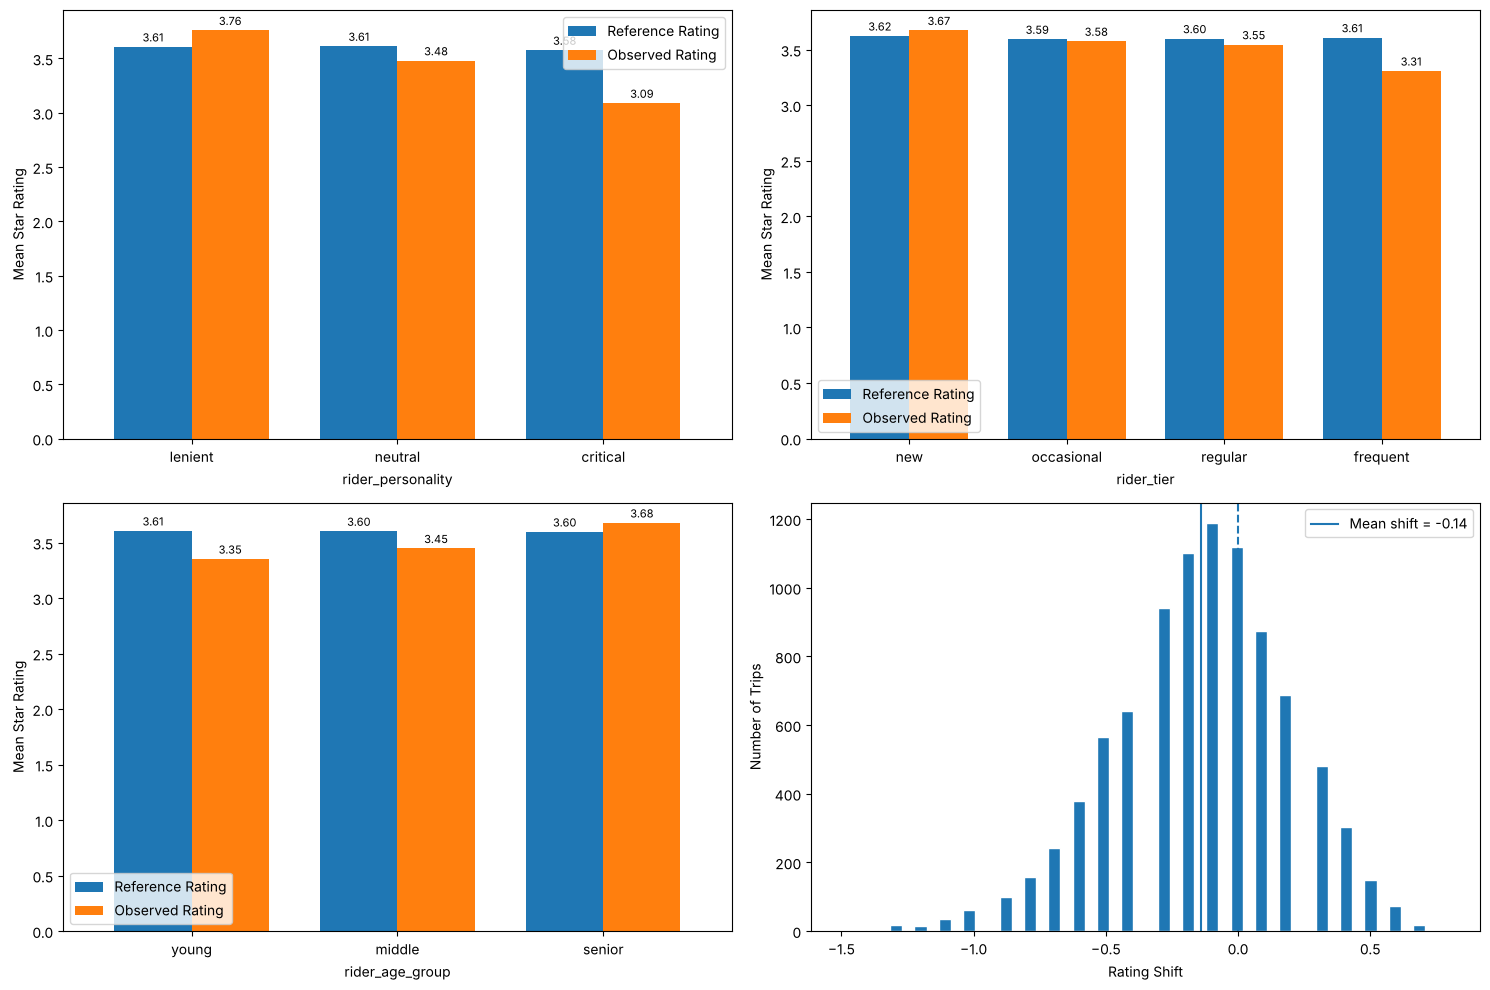

Mean reference rating: 3.602
Mean observed rating: 3.461
Shift of at least 0.3: 4188
Shift of at least 0.5: 1823


In [8]:
import matplotlib.pyplot as plt

def plot_group_comparison(ax, data, group_col, order):
    summary = data.groupby(group_col)[["original_star_rating", "star_rating"]].mean().reindex(order).dropna()
    summary.plot(kind="bar", ax=ax, width=0.75)
    ax.set_ylabel("Mean Star Rating")
    ax.set_xlabel(group_col)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(["Reference Rating", "Observed Rating"])
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plot_group_comparison(axes[0, 0], df, "rider_personality", ["lenient", "neutral", "critical"])
plot_group_comparison(axes[0, 1], df, "rider_tier", ["new", "occasional", "regular", "frequent"])
plot_group_comparison(axes[1, 0], df, "rider_age_group", ["young", "middle", "senior"])
axes[1, 1].hist(df["rating_shift"], bins=50, edgecolor="white")
axes[1, 1].axvline(0, linestyle="--", linewidth=1.5)
axes[1, 1].axvline(df["rating_shift"].mean(), linewidth=1.5, label=f"Mean shift = {df['rating_shift'].mean():.2f}")
axes[1, 1].set_xlabel("Rating Shift")
axes[1, 1].set_ylabel("Number of Trips")
axes[1, 1].legend()
plt.tight_layout()
plt.savefig("bias_verification.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Mean reference rating: {df['original_star_rating'].mean():.3f}")
print(f"Mean observed rating: {df['star_rating'].mean():.3f}")
print(f"Shift of at least 0.3: {(df['rating_shift'].abs() >= 0.3).sum()}")
print(f"Shift of at least 0.5: {(df['rating_shift'].abs() >= 0.5).sum()}")